In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the NASA POWER weather dataset
weather = pd.read_csv(
    "POWER_Point_Hourly_20240101_20250624_017d39N_078d49E_LST.csv",
    skiprows=13
)

# Load the solar generation dataset
solar = pd.read_csv("solar_ready.csv")

In [4]:
# Display the first five rows of weather data
weather.head()


,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,T2MDEW,RH2M,WS10M
0,2024,1,1,0,0.0,16.34,15.38,94.13,2.68
1,2024,1,1,1,0.0,15.81,15.99,100.00,2.57
2,2024,1,1,2,0.0,15.60,16.44,100.00,2.40
3,2024,1,1,3,0.0,15.39,16.68,100.00,2.25
4,2024,1,1,4,0.0,15.60,16.74,100.00,2.09


In [5]:
# Display the first five rows of solar data
solar.head()

,Timestamp,Solar (MW)
0,2024-01-01 00:00:00,20.29
1,2024-01-01 01:00:00,19.96
2,2024-01-01 02:00:00,19.79
3,2024-01-01 03:00:00,19.73
4,2024-01-01 04:00:00,20.02


In [6]:
# Check the number of rows and columns

print("Weather Dataset Shape:", weather.shape)
print("Solar Dataset Shape:", solar.shape)

Weather Dataset Shape: (12984, 9)
Solar Dataset Shape: (12984, 2)


In [7]:
# Display weather dataset column names
print("Weather Columns:")
print(weather.columns)

# Display solar dataset column names
print("\nSolar Columns:")
print(solar.columns)

Weather Columns:
Index(['YEAR', 'MO', 'DY', 'HR', 'ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M',
       'WS10M'],
      dtype='str')

Solar Columns:
Index(['Timestamp', 'Solar (MW)'], dtype='str')


In [8]:
# Check weather dataset information
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 12984 entries, 0 to 12983
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   YEAR               12984 non-null  int64  
 1   MO                 12984 non-null  int64  
 2   DY                 12984 non-null  int64  
 3   HR                 12984 non-null  int64  
 4   ALLSKY_SFC_SW_DWN  12984 non-null  float64
 5   T2M                12984 non-null  float64
 6   T2MDEW             12984 non-null  float64
 7   RH2M               12984 non-null  float64
 8   WS10M              12984 non-null  float64
dtypes: float64(5), int64(4)
memory usage: 913.1 KB


In [9]:
# Check solar dataset information
solar.info()

<class 'pandas.DataFrame'>
RangeIndex: 12984 entries, 0 to 12983
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Timestamp   12984 non-null  str    
 1   Solar (MW)  12984 non-null  float64
dtypes: float64(1), str(1)
memory usage: 203.0 KB


In [10]:
# Statistical summary of weather data
weather.describe()

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,T2MDEW,RH2M,WS10M
count,12984.000000,12984.000000,12984.000000,12984.000000,12984.000000,12984.000000,12984.000000,12984.000000,12984.000000
mean,2024.323475,5.513863,15.574861,11.500000,213.672852,26.838319,16.414580,59.886577,3.619829
std,0.467820,3.325143,8.745044,6.922453,289.191157,5.947367,5.961577,26.002385,1.908401
min,2024.000000,1.000000,1.000000,0.000000,0.000000,8.960000,-14.100000,3.270000,0.010000
25%,2024.000000,3.000000,8.000000,5.750000,0.000000,23.090000,12.090000,36.970000,2.340000
50%,2024.000000,5.000000,16.000000,11.500000,8.785000,26.360000,17.400000,61.985000,3.160000
75%,2025.000000,8.000000,23.000000,17.250000,427.335000,30.480000,21.710000,83.800000,4.500000
max,2025.000000,12.000000,31.000000,23.000000,1024.250000,43.880000,25.370000,100.000000,12.590000


In [11]:
# Statistical summary of solar data
solar.describe()

,Solar (MW)
count,12984.000000
mean,15624.212649
std,19807.778052
min,0.000000
25%,102.647500
50%,1776.245000
75%,33409.710000
max,64701.190000


In [12]:
# Check missing values in weather data
print("Weather Missing Values:")
print(weather.isnull().sum())

# Check missing values in solar data
print("\nSolar Missing Values:")
print(solar.isnull().sum())

Weather Missing Values:
YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
dtype: int64

Solar Missing Values:
Timestamp     0
Solar (MW)    0
dtype: int64


In [13]:
# Check duplicate rows in weather data
print("Weather Duplicates:", weather.duplicated().sum())

# Check duplicate rows in solar data
print("Solar Duplicates:", solar.duplicated().sum())

Weather Duplicates: 0
Solar Duplicates: 0


In [14]:
# Display unique values in the weather columns

print("YEAR:", weather["YEAR"].unique())
print("MO:", weather["MO"].unique())
print("DY:", weather["DY"].unique())
print("HR:", weather["HR"].unique())

print("Solar Irradiance Minimum:",
      weather["ALLSKY_SFC_SW_DWN"].min())

print("Solar Irradiance Maximum:",
      weather["ALLSKY_SFC_SW_DWN"].max())

print("Temperature Minimum:", weather["T2M"].min())
print("Temperature Maximum:", weather["T2M"].max())

print("Humidity Minimum:", weather["RH2M"].min())
print("Humidity Maximum:", weather["RH2M"].max())

print("Wind Speed Minimum:", weather["WS10M"].min())
print("Wind Speed Maximum:", weather["WS10M"].max())

YEAR: [2024 2025]
MO: [ 1  2  3  4  5  6  7  8  9 10 11 12]
DY: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]
HR: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Solar Irradiance Minimum: 0.0
Solar Irradiance Maximum: 1024.25
Temperature Minimum: 8.96
Temperature Maximum: 43.88
Humidity Minimum: 3.27
Humidity Maximum: 100.0
Wind Speed Minimum: 0.01
Wind Speed Maximum: 12.59


In [15]:
# Check for NASA's missing-data indicator

print("NASA missing indicator count:")

print((weather == -999).sum())

NASA missing indicator count:
YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
dtype: int64


In [16]:
# Check solar generation statistics

print("Minimum Generation:", solar["Solar (MW)"].min())
print("Maximum Generation:", solar["Solar (MW)"].max())
print("Average Generation:", solar["Solar (MW)"].mean())
print("Median Generation:", solar["Solar (MW)"].median())

print("\nNegative Generation Values:")
print((solar["Solar (MW)"] < 0).sum())

print("\nZero Generation Values:")
print((solar["Solar (MW)"] == 0).sum())

Minimum Generation: 0.0
Maximum Generation: 64701.19
Average Generation: 15624.212649414663
Median Generation: 1776.245

Negative Generation Values:
0

Zero Generation Values:
701


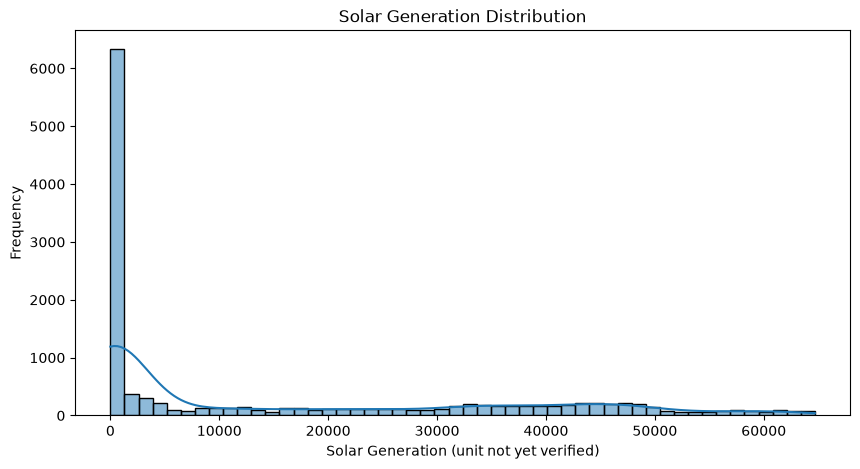

In [17]:
# Plot solar generation distribution

plt.figure(figsize=(10, 5))

sns.histplot(solar["Solar (MW)"], bins=50, kde=True)

plt.title("Solar Generation Distribution")
plt.xlabel("Solar Generation (unit not yet verified)")
plt.ylabel("Frequency")

plt.show()

In [18]:
# Convert the solar timestamp column into datetime format

solar["Timestamp"] = pd.to_datetime(solar["Timestamp"])

# Create a timestamp from the NASA date and hour columns

weather["Timestamp"] = pd.to_datetime(
    weather[["YEAR", "MO", "DY", "HR"]].rename(
        columns={
            "YEAR": "year",
            "MO": "month",
            "DY": "day",
            "HR": "hour"
        }
    )
)

# Display the timestamps

print("Solar Timestamp:")
print(solar["Timestamp"].head())

print("\nWeather Timestamp:")
print(weather["Timestamp"].head())

Solar Timestamp:
0   2024-01-01 00:00:00
1   2024-01-01 01:00:00
2   2024-01-01 02:00:00
3   2024-01-01 03:00:00
4   2024-01-01 04:00:00
Name: Timestamp, dtype: datetime64[us]

Weather Timestamp:
0   2024-01-01 00:00:00
1   2024-01-01 01:00:00
2   2024-01-01 02:00:00
3   2024-01-01 03:00:00
4   2024-01-01 04:00:00
Name: Timestamp, dtype: datetime64[us]


In [19]:
# Check the first and last timestamps

print("Solar Start:", solar["Timestamp"].min())
print("Solar End:", solar["Timestamp"].max())

print("\nWeather Start:", weather["Timestamp"].min())
print("Weather End:", weather["Timestamp"].max())

Solar Start: 2024-01-01 00:00:00
Solar End: 2025-06-24 23:00:00

Weather Start: 2024-01-01 00:00:00
Weather End: 2025-06-24 23:00:00


In [20]:
# Check duplicate timestamps

print("Solar Duplicate Timestamps:",
      solar["Timestamp"].duplicated().sum())

print("Weather Duplicate Timestamps:",
      weather["Timestamp"].duplicated().sum())

Solar Duplicate Timestamps: 0
Weather Duplicate Timestamps: 0


In [21]:
# Sort both datasets by timestamp

solar = solar.sort_values("Timestamp").reset_index(drop=True)

weather = weather.sort_values("Timestamp").reset_index(drop=True)

# Calculate the time difference between consecutive records

solar_time_difference = solar["Timestamp"].diff()

weather_time_difference = weather["Timestamp"].diff()

# Count gaps that are not equal to one hour

print("Solar Non-Hourly Gaps:",
      (solar_time_difference.iloc[1:] != pd.Timedelta(hours=1)).sum())

print("Weather Non-Hourly Gaps:",
      (weather_time_difference.iloc[1:] != pd.Timedelta(hours=1)).sum())

Solar Non-Hourly Gaps: 0
Weather Non-Hourly Gaps: 0


In [22]:
# Check whether every solar timestamp exists in weather data

solar_timestamp_match = solar["Timestamp"].isin(weather["Timestamp"])

print("Matching Solar Timestamps:",
      solar_timestamp_match.sum())

print("Unmatched Solar Timestamps:",
      (~solar_timestamp_match).sum())

# Check whether every weather timestamp exists in solar data

weather_timestamp_match = weather["Timestamp"].isin(solar["Timestamp"])

print("\nMatching Weather Timestamps:",
      weather_timestamp_match.sum())

print("Unmatched Weather Timestamps:",
      (~weather_timestamp_match).sum())

Matching Solar Timestamps: 12984
Unmatched Solar Timestamps: 0

Matching Weather Timestamps: 12984
Unmatched Weather Timestamps: 0


In [23]:
# Display the weather columns and their known units

weather_units = pd.DataFrame({
    "Feature": [
        "ALLSKY_SFC_SW_DWN",
        "T2M",
        "T2MDEW",
        "RH2M",
        "WS10M"
    ],
    "Description": [
        "All Sky Surface Shortwave Downward Irradiance",
        "Temperature at 2 Meters",
        "Dew/Frost Point at 2 Meters",
        "Relative Humidity at 2 Meters",
        "Wind Speed at 10 Meters"
    ],
    "Unit": [
        "Wh/m²",
        "°C",
        "°C",
        "%",
        "m/s"
    ]
})

weather_units

,Feature,Description,Unit
0,ALLSKY_SFC_SW_DWN,All Sky Surface Shortwave Downward Irradiance,Wh/m²
1,T2M,Temperature at 2 Meters,°C
2,T2MDEW,Dew/Frost Point at 2 Meters,°C
3,RH2M,Relative Humidity at 2 Meters,%
4,WS10M,Wind Speed at 10 Meters,m/s


In [24]:
# Display the available solar-generation information

print("Solar Dataset Columns:")
print(solar.columns)

print("\nSolar Generation Statistics:")
print(solar["Solar (MW)"].describe())

print("\nSolar Generation Sample:")
print(solar.head(10))

Solar Dataset Columns:
Index(['Timestamp', 'Solar (MW)'], dtype='str')

Solar Generation Statistics:
count    12984.000000
mean     15624.212649
std      19807.778052
min          0.000000
25%        102.647500
50%       1776.245000
75%      33409.710000
max      64701.190000
Name: Solar (MW), dtype: float64

Solar Generation Sample:
            Timestamp  Solar (MW)
0 2024-01-01 00:00:00       20.29
1 2024-01-01 01:00:00       19.96
2 2024-01-01 02:00:00       19.79
3 2024-01-01 03:00:00       19.73
4 2024-01-01 04:00:00       20.02
5 2024-01-01 05:00:00       18.55
6 2024-01-01 06:00:00      107.84
7 2024-01-01 07:00:00     1570.77
8 2024-01-01 08:00:00     9518.41
9 2024-01-01 09:00:00    19207.05


In [25]:
# Compare the timestamp columns

if solar["Timestamp"].equals(weather["Timestamp"]):
    print("Both timestamp columns match exactly.")
else:
    print("The timestamp columns do not match exactly.")

Both timestamp columns match exactly.


In [26]:
# Merge the datasets using their timestamps

solar_weather = pd.merge(
    weather,
    solar,
    on="Timestamp",
    how="inner"
)

# Display the merged dataset

solar_weather.head()

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,T2MDEW,RH2M,WS10M,Timestamp,Solar (MW)
0,2024,1,1,0,0.0,16.34,15.38,94.13,2.68,2024-01-01 00:00:00,20.29
1,2024,1,1,1,0.0,15.81,15.99,100.00,2.57,2024-01-01 01:00:00,19.96
2,2024,1,1,2,0.0,15.60,16.44,100.00,2.40,2024-01-01 02:00:00,19.79
3,2024,1,1,3,0.0,15.39,16.68,100.00,2.25,2024-01-01 03:00:00,19.73
4,2024,1,1,4,0.0,15.60,16.74,100.00,2.09,2024-01-01 04:00:00,20.02


In [27]:
# Check the final merged dataset

print("Merged Dataset Shape:", solar_weather.shape)

print("\nMerged Dataset Columns:")
print(solar_weather.columns)

print("\nMissing Values:")
print(solar_weather.isnull().sum())

print("\nDuplicate Rows:")
print(solar_weather.duplicated().sum())

print("\nTimestamp Start:")
print(solar_weather["Timestamp"].min())

print("\nTimestamp End:")
print(solar_weather["Timestamp"].max())

Merged Dataset Shape: (12984, 11)

Merged Dataset Columns:
Index(['YEAR', 'MO', 'DY', 'HR', 'ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M',
       'WS10M', 'Timestamp', 'Solar (MW)'],
      dtype='str')

Missing Values:
YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
Timestamp            0
Solar (MW)           0
dtype: int64

Duplicate Rows:
0

Timestamp Start:
2024-01-01 00:00:00

Timestamp End:
2025-06-24 23:00:00


In [28]:
# Check whether merged timestamps are one hour apart

merged_time_difference = solar_weather["Timestamp"].diff()

print(
    "Non-Hourly Gaps:",
    (merged_time_difference.iloc[1:] != pd.Timedelta(hours=1)).sum()
)

Non-Hourly Gaps: 0


In [29]:
# Display generation values when NASA irradiance is zero

night_time_data = solar_weather[
    solar_weather["ALLSKY_SFC_SW_DWN"] == 0
]

print("Records with zero irradiance:", night_time_data.shape[0])

print("\nGeneration statistics during zero irradiance:")
print(night_time_data["Solar (MW)"].describe())

# Display some of these records

night_time_data[["Timestamp", "ALLSKY_SFC_SW_DWN", "Solar (MW)"]].head(10)

Records with zero irradiance: 6232

Generation statistics during zero irradiance:
count     6232.000000
mean       711.592839
std       4375.206770
min          0.000000
25%         37.462500
50%        106.820000
75%        252.792500
max      64300.610000
Name: Solar (MW), dtype: float64


,Timestamp,ALLSKY_SFC_SW_DWN,Solar (MW)
0,2024-01-01 00:00:00,0.0,20.29
1,2024-01-01 01:00:00,0.0,19.96
2,2024-01-01 02:00:00,0.0,19.79
3,2024-01-01 03:00:00,0.0,19.73
4,2024-01-01 04:00:00,0.0,20.02
5,2024-01-01 05:00:00,0.0,18.55
18,2024-01-01 18:00:00,0.0,93.96
19,2024-01-01 19:00:00,0.0,42.23
20,2024-01-01 20:00:00,0.0,0.90
21,2024-01-01 21:00:00,0.0,0.00


In [31]:
# Display the merged dataset

solar_weather.head()

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,T2MDEW,RH2M,WS10M,Timestamp,Solar (MW)
0,2024,1,1,0,0.0,16.34,15.38,94.13,2.68,2024-01-01 00:00:00,20.29
1,2024,1,1,1,0.0,15.81,15.99,100.00,2.57,2024-01-01 01:00:00,19.96
2,2024,1,1,2,0.0,15.60,16.44,100.00,2.40,2024-01-01 02:00:00,19.79
3,2024,1,1,3,0.0,15.39,16.68,100.00,2.25,2024-01-01 03:00:00,19.73
4,2024,1,1,4,0.0,15.60,16.74,100.00,2.09,2024-01-01 04:00:00,20.02


In [32]:
# Check dataset dimensions
print("Dataset Shape:", solar_weather.shape)

# Check column names
print("\nDataset Columns:")
print(solar_weather.columns)

# Check data types
print("\nDataset Information:")
solar_weather.info()

Dataset Shape: (12984, 11)

Dataset Columns:
Index(['YEAR', 'MO', 'DY', 'HR', 'ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M',
       'WS10M', 'Timestamp', 'Solar (MW)'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12984 entries, 0 to 12983
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   YEAR               12984 non-null  int64         
 1   MO                 12984 non-null  int64         
 2   DY                 12984 non-null  int64         
 3   HR                 12984 non-null  int64         
 4   ALLSKY_SFC_SW_DWN  12984 non-null  float64       
 5   T2M                12984 non-null  float64       
 6   T2MDEW             12984 non-null  float64       
 7   RH2M               12984 non-null  float64       
 8   WS10M              12984 non-null  float64       
 9   Timestamp          12984 non-null  datetime64[us]
 10  Solar (MW)         12984 non

In [33]:
# Check missing values
print("Missing Values:")
print(solar_weather.isnull().sum())

# Check NASA missing-data indicators
print("\nNASA -999 Values:")
print((solar_weather == -999).sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(solar_weather.duplicated().sum())

# Check duplicate timestamps
print("\nDuplicate Timestamps:")
print(solar_weather["Timestamp"].duplicated().sum())

Missing Values:
YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
Timestamp            0
Solar (MW)           0
dtype: int64

NASA -999 Values:
YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
Timestamp            0
Solar (MW)           0
dtype: int64

Duplicate Rows:
0

Duplicate Timestamps:
0


In [34]:
# Replace NASA's -999 values with missing values

weather_columns = [
    "ALLSKY_SFC_SW_DWN",
    "T2M",
    "T2MDEW",
    "RH2M",
    "WS10M"
]

for column in weather_columns:
    solar_weather.loc[
        solar_weather[column] == -999, column
    ] = np.nan

# Check missing values again

solar_weather.isnull().sum()

YEAR                 0
MO                   0
DY                   0
HR                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
Timestamp            0
Solar (MW)           0
dtype: int64

In [35]:
# Remove rows missing important model information

required_columns = [
    "Timestamp",
    "ALLSKY_SFC_SW_DWN",
    "T2M",
    "T2MDEW",
    "RH2M",
    "WS10M",
    "Solar (MW)"
]

solar_weather = solar_weather.dropna(
    subset=required_columns
)

# Reset the row numbers

solar_weather = solar_weather.reset_index(drop=True)

# Check the remaining dataset

print("Dataset Shape:", solar_weather.shape)

print("\nMissing Values:")
print(solar_weather[required_columns].isnull().sum())

Dataset Shape: (12984, 11)

Missing Values:
Timestamp            0
ALLSKY_SFC_SW_DWN    0
T2M                  0
T2MDEW               0
RH2M                 0
WS10M                0
Solar (MW)           0
dtype: int64


In [36]:
# Check the target statistics

print("Minimum:", solar_weather["Solar (MW)"].min())
print("Maximum:", solar_weather["Solar (MW)"].max())
print("Mean:", solar_weather["Solar (MW)"].mean())
print("Median:", solar_weather["Solar (MW)"].median())

# Check negative values

print(
    "Negative Generation Values:",
    (solar_weather["Solar (MW)"] < 0).sum()
)

Minimum: 0.0
Maximum: 64701.19
Mean: 15624.212649414663
Median: 1776.245
Negative Generation Values: 0


In [37]:
# Extract hour and month from the timestamp

solar_weather["Hour"] = solar_weather["Timestamp"].dt.hour

solar_weather["Month"] = solar_weather["Timestamp"].dt.month

solar_weather["Day"] = solar_weather["Timestamp"].dt.day

solar_weather["DayOfYear"] = solar_weather["Timestamp"].dt.dayofyear

# Display the new features

solar_weather[
    ["Timestamp", "Hour", "Day", "Month", "DayOfYear"]
].head()

,Timestamp,Hour,Day,Month,DayOfYear
0,2024-01-01 00:00:00,0,1,1,1
1,2024-01-01 01:00:00,1,1,1,1
2,2024-01-01 02:00:00,2,1,1,1
3,2024-01-01 03:00:00,3,1,1,1
4,2024-01-01 04:00:00,4,1,1,1


In [38]:
# Select weather and time-related input features

feature_columns = [
    "ALLSKY_SFC_SW_DWN",
    "T2M",
    "T2MDEW",
    "RH2M",
    "WS10M",
    "Hour",
    "Month",
    "DayOfYear"
]

X = solar_weather[feature_columns]

# Select the target column

y = solar_weather["Solar (MW)"]

# Display the inputs and target

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   ALLSKY_SFC_SW_DWN    T2M  T2MDEW    RH2M  WS10M  Hour  Month  DayOfYear
0                0.0  16.34   15.38   94.13   2.68     0      1          1
1                0.0  15.81   15.99  100.00   2.57     1      1          1
2                0.0  15.60   16.44  100.00   2.40     2      1          1
3                0.0  15.39   16.68  100.00   2.25     3      1          1
4                0.0  15.60   16.74  100.00   2.09     4      1          1

Target:
0    20.29
1    19.96
2    19.79
3    19.73
4    20.02
Name: Solar (MW), dtype: float64


In [39]:
# Check the dimensions

print("Input Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Feature Names:")
print(X.columns.tolist())

Input Shape: (12984, 8)
Target Shape: (12984,)

Input Feature Names:
['ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M', 'WS10M', 'Hour', 'Month', 'DayOfYear']


In [40]:
# Check whether the target is included in the input features

if "Solar (MW)" in X.columns:
    print("Warning: Target leakage detected.")
else:
    print("No direct target-column leakage detected.")

# Check whether timestamp is included as an input

if "Timestamp" in X.columns:
    print("Timestamp column is included.")
else:
    print("Raw timestamp is not included in the input features.")

No direct target-column leakage detected.
Raw timestamp is not included in the input features.


In [41]:
# Sort the dataset by timestamp

solar_weather = solar_weather.sort_values(
    "Timestamp"
).reset_index(drop=True)

# Find the total number of records

total_records = len(solar_weather)

# Calculate the split positions

train_end = int(total_records * 0.70)

validation_end = int(total_records * 0.85)

# Split the input data

X_train = X.iloc[:train_end]
X_validation = X.iloc[train_end:validation_end]
X_test = X.iloc[validation_end:]

# Split the target data

y_train = y.iloc[:train_end]
y_validation = y.iloc[train_end:validation_end]
y_test = y.iloc[validation_end:]

# Display the sizes

print("Training Records:", len(X_train))
print("Validation Records:", len(X_validation))
print("Testing Records:", len(X_test))

Training Records: 9088
Validation Records: 1948
Testing Records: 1948


In [42]:
# Display the date ranges

print("Training Period:")
print(solar_weather["Timestamp"].iloc[0])
print(solar_weather["Timestamp"].iloc[train_end - 1])

print("\nValidation Period:")
print(solar_weather["Timestamp"].iloc[train_end])
print(solar_weather["Timestamp"].iloc[validation_end - 1])

print("\nTesting Period:")
print(solar_weather["Timestamp"].iloc[validation_end])
print(solar_weather["Timestamp"].iloc[-1])

Training Period:
2024-01-01 00:00:00
2025-01-13 15:00:00

Validation Period:
2025-01-13 16:00:00
2025-04-04 19:00:00

Testing Period:
2025-04-04 20:00:00
2025-06-24 23:00:00


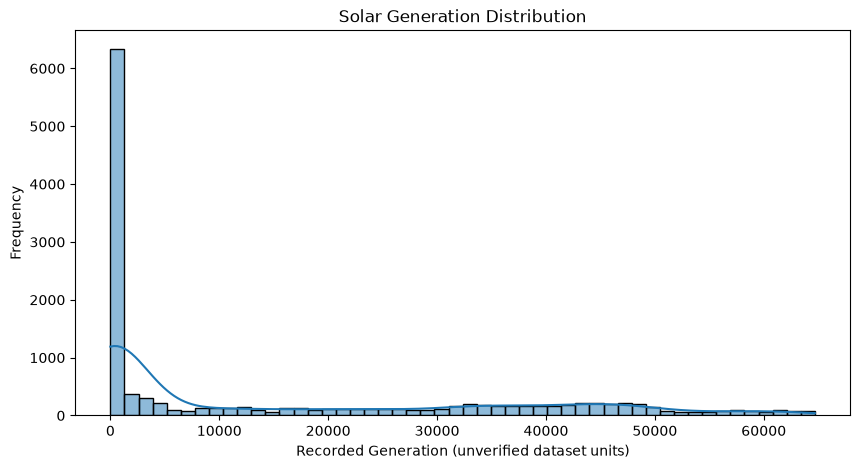

In [43]:
# Plot the distribution of solar generation

plt.figure(figsize=(10, 5))

sns.histplot(y, bins=50, kde=True)

plt.title("Solar Generation Distribution")
plt.xlabel("Recorded Generation (unverified dataset units)")
plt.ylabel("Frequency")

plt.show()

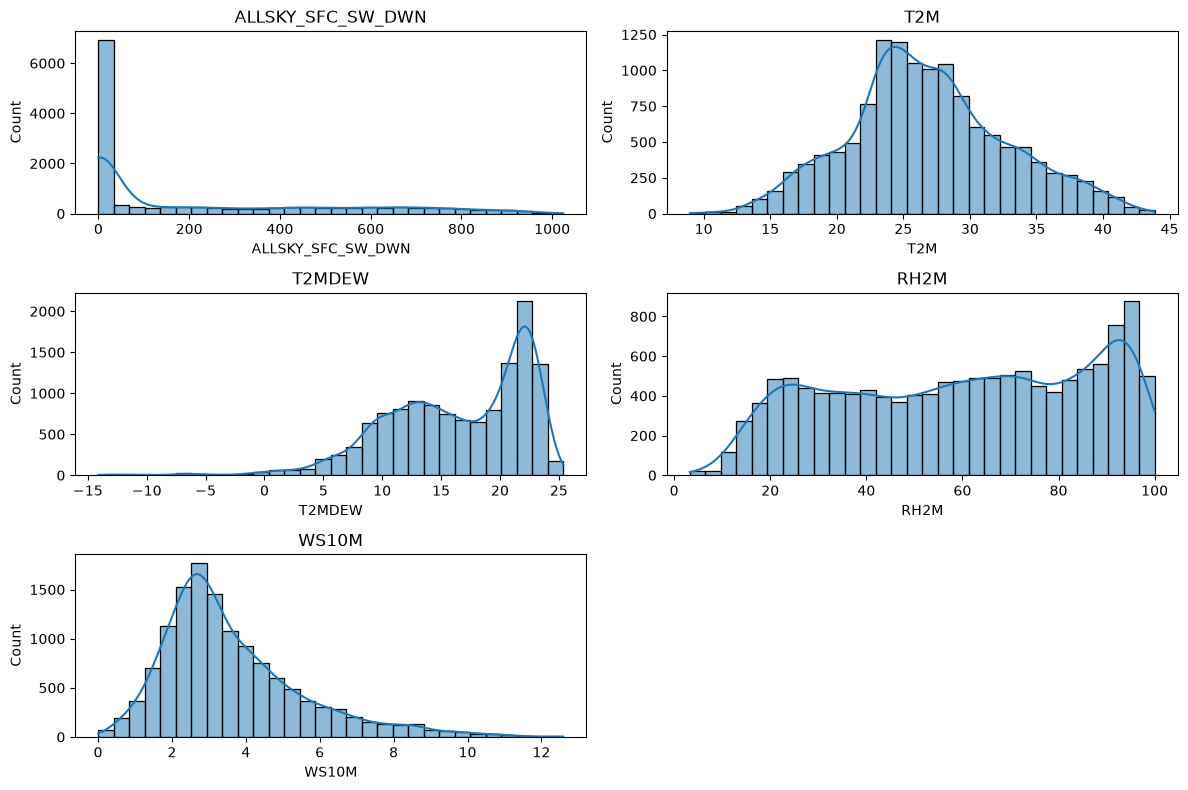

In [44]:
# Plot weather feature distributions

plt.figure(figsize=(12, 8))

for i, column in enumerate(weather_columns):
    plt.subplot(3, 2, i + 1)
    sns.histplot(solar_weather[column], bins=30, kde=True)
    plt.title(column)

plt.tight_layout()

plt.show()

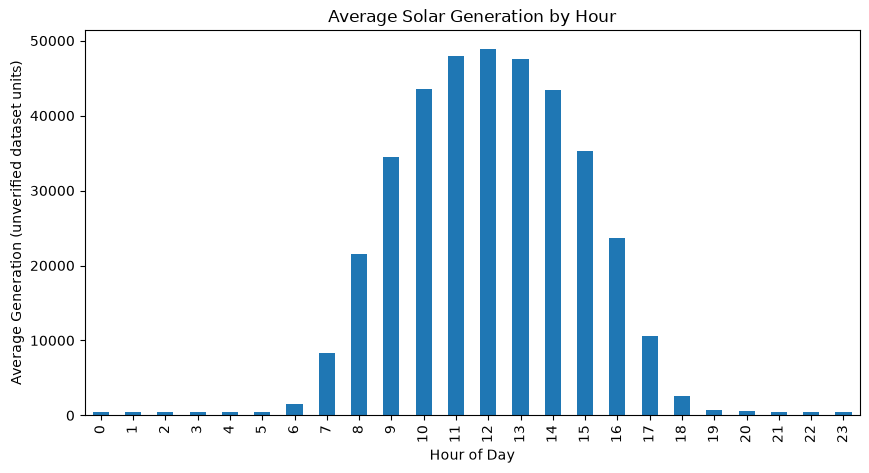

In [45]:
# Calculate average generation for each hour

hourly_generation = solar_weather.groupby(
    "Hour"
)["Solar (MW)"].mean()

# Plot average generation by hour

plt.figure(figsize=(10, 5))

hourly_generation.plot(kind="bar")

plt.title("Average Solar Generation by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Generation (unverified dataset units)")

plt.show()

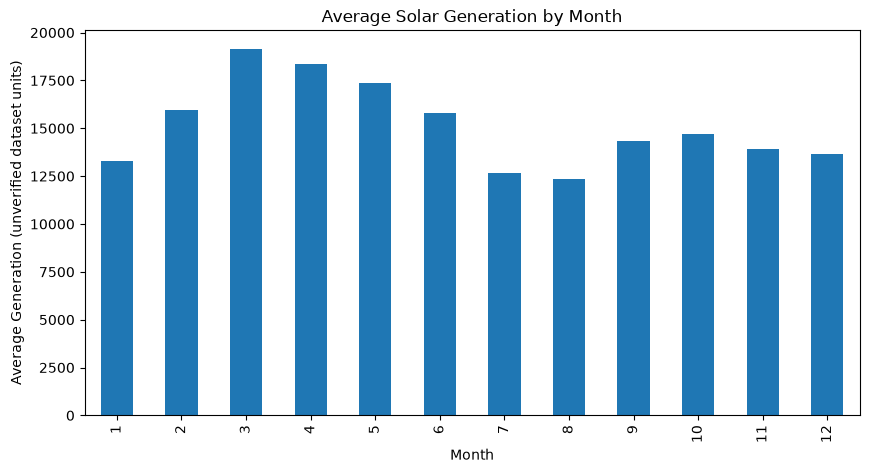

In [46]:
# Calculate average generation for each month

monthly_generation = solar_weather.groupby(
    "Month"
)["Solar (MW)"].mean()

# Plot monthly generation

plt.figure(figsize=(10, 5))

monthly_generation.plot(kind="bar")

plt.title("Average Solar Generation by Month")
plt.xlabel("Month")
plt.ylabel("Average Generation (unverified dataset units)")

plt.show()

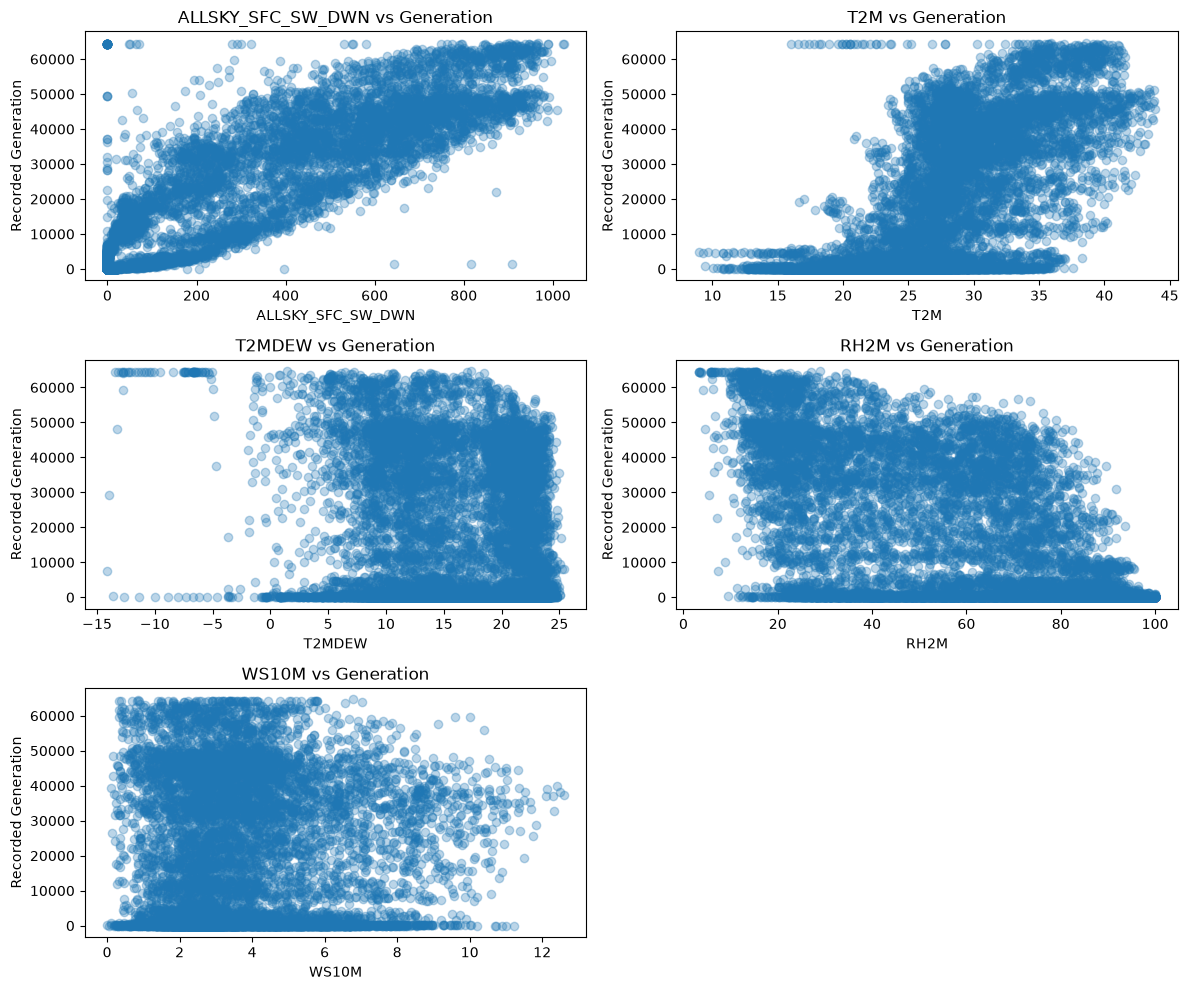

In [47]:
# Plot weather features against solar generation

plt.figure(figsize=(12, 10))

for i, column in enumerate(weather_columns):
    plt.subplot(3, 2, i + 1)

    plt.scatter(
        solar_weather[column],
        solar_weather["Solar (MW)"],
        alpha=0.3
    )

    plt.xlabel(column)
    plt.ylabel("Recorded Generation")
    plt.title(column + " vs Generation")

plt.tight_layout()

plt.show()

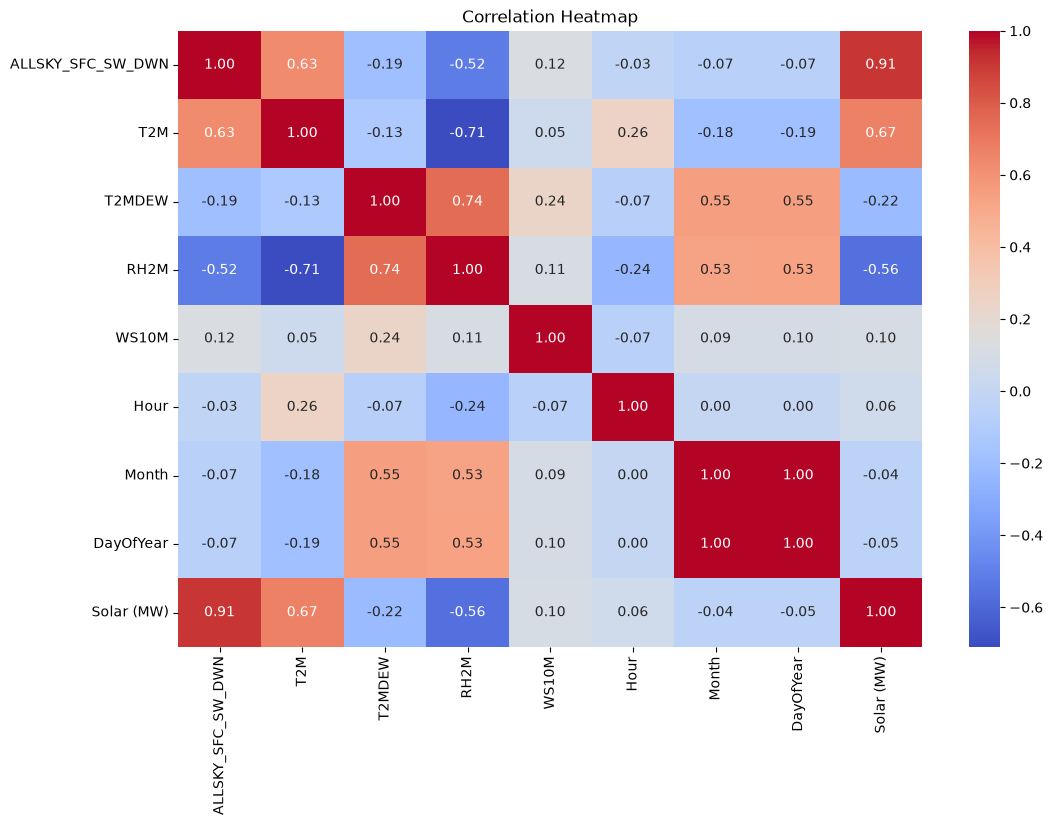

In [48]:
# Select numerical columns for correlation

correlation_data = solar_weather[
    feature_columns + ["Solar (MW)"]
]

# Calculate correlation

correlation_matrix = correlation_data.corr()

# Plot correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [49]:
# Display correlation values with the target

generation_correlation = correlation_matrix["Solar (MW)"].sort_values(
    ascending=False
)

print(generation_correlation)

Solar (MW)           1.000000
ALLSKY_SFC_SW_DWN    0.912652
T2M                  0.672640
WS10M                0.100516
Hour                 0.064970
Month               -0.044575
DayOfYear           -0.045823
T2MDEW              -0.216069
RH2M                -0.564572
Name: Solar (MW), dtype: float64


In [50]:
# Import regression models

from sklearn.linear_model import LinearRegression, Ridge

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor

# Import scaling

from sklearn.preprocessing import StandardScaler

# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [51]:
# Create the scaler

scaler = StandardScaler()

# Fit the scaler using training data only

X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test data

X_validation_scaled = scaler.transform(X_validation)

X_test_scaled = scaler.transform(X_test)

In [52]:
# Create the Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train, y_train)

# Predict validation values

linear_validation_pred = linear_model.predict(X_validation)

print("Linear Regression training completed.")

Linear Regression training completed.


In [53]:
# Create the Ridge Regression model

ridge_model = Ridge(alpha=1.0)

# Train using scaled training data

ridge_model.fit(X_train_scaled, y_train)

# Predict validation values

ridge_validation_pred = ridge_model.predict(X_validation_scaled)

print("Ridge Regression training completed.")

Ridge Regression training completed.


In [54]:
# Create the Decision Tree model

tree_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train the model

tree_model.fit(X_train, y_train)

# Predict validation values

tree_validation_pred = tree_model.predict(X_validation)

print("Decision Tree training completed.")

Decision Tree training completed.


In [55]:
# Create the Random Forest model

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model

forest_model.fit(X_train, y_train)

# Predict validation values

forest_validation_pred = forest_model.predict(X_validation)

print("Random Forest training completed.")

Random Forest training completed.


In [56]:
# Create a simple function to calculate evaluation metrics

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

In [57]:
# Evaluate Linear Regression

linear_mae, linear_rmse, linear_r2 = evaluate_model(
    y_validation,
    linear_validation_pred
)

# Evaluate Ridge Regression

ridge_mae, ridge_rmse, ridge_r2 = evaluate_model(
    y_validation,
    ridge_validation_pred
)

# Evaluate Decision Tree

tree_mae, tree_rmse, tree_r2 = evaluate_model(
    y_validation,
    tree_validation_pred
)

# Evaluate Random Forest

forest_mae, forest_rmse, forest_r2 = evaluate_model(
    y_validation,
    forest_validation_pred
)

# Create a comparison table

initial_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        tree_mae,
        forest_mae
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        tree_rmse,
        forest_rmse
    ],
    "R2": [
        linear_r2,
        ridge_r2,
        tree_r2,
        forest_r2
    ]
})

initial_results

,Model,MAE,RMSE,R2
0,Linear Regression,7887.585120,12732.162810,0.730202
1,Ridge Regression,7883.928589,12728.081139,0.730375
2,Decision Tree,6029.245546,11551.224812,0.777930
3,Random Forest,5937.258817,11322.547704,0.786636


In [58]:
# Import tools for time-series model tuning

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [59]:
# Create time-series cross-validation

time_split = TimeSeriesSplit(n_splits=3)

# Define the Decision Tree settings to test

tree_parameters = {
    "max_depth": [5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Create the tuning process

tree_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    tree_parameters,
    cv=time_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Tune using training data only

tree_search.fit(X_train, y_train)

# Display the best settings

print("Best Decision Tree Parameters:")
print(tree_search.best_params_)

Best Decision Tree Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}


In [60]:
# Define the Random Forest settings to test

forest_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 20],
    "min_samples_leaf": [1, 2]
}

# Create the tuning process

forest_search = GridSearchCV(
    RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    forest_parameters,
    cv=time_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Tune using training data only

forest_search.fit(X_train, y_train)

# Display the best settings

print("Best Random Forest Parameters:")
print(forest_search.best_params_)

Best Random Forest Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}


In [61]:
# Store the best tuned models

best_tree_model = tree_search.best_estimator_

best_forest_model = forest_search.best_estimator_

# Generate validation predictions

best_tree_validation_pred = best_tree_model.predict(X_validation)

best_forest_validation_pred = best_forest_model.predict(X_validation)

print("Tuned models are ready.")

Tuned models are ready.


In [62]:
# Calculate tuned Decision Tree metrics

best_tree_mae, best_tree_rmse, best_tree_r2 = evaluate_model(
    y_validation,
    best_tree_validation_pred
)

# Calculate tuned Random Forest metrics

best_forest_mae, best_forest_rmse, best_forest_r2 = evaluate_model(
    y_validation,
    best_forest_validation_pred
)

# Create the final validation comparison

validation_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Decision Tree",
        "Tuned Random Forest"
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        tree_mae,
        forest_mae,
        best_tree_mae,
        best_forest_mae
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        tree_rmse,
        forest_rmse,
        best_tree_rmse,
        best_forest_rmse
    ],
    "R2": [
        linear_r2,
        ridge_r2,
        tree_r2,
        forest_r2,
        best_tree_r2,
        best_forest_r2
    ]
})

# Sort models by validation MAE

validation_results = validation_results.sort_values(
    by="MAE"
).reset_index(drop=True)

validation_results

,Model,MAE,RMSE,R2
0,Tuned Random Forest,5859.578774,11229.997458,0.790109
1,Random Forest,5937.258817,11322.547704,0.786636
2,Tuned Decision Tree,5944.917135,11384.997080,0.784276
3,Decision Tree,6029.245546,11551.224812,0.777930
4,Ridge Regression,7883.928589,12728.081139,0.730375
5,Linear Regression,7887.585120,12732.162810,0.730202


In [63]:
# Select the model with the lowest validation MAE

best_model_name = validation_results.iloc[0]["Model"]

print("Best Validation Model:", best_model_name)

Best Validation Model: Tuned Random Forest


In [64]:
# Select the model based on validation results

if best_model_name == "Linear Regression":
    best_model = linear_model

elif best_model_name == "Ridge Regression":
    best_model = ridge_model

elif best_model_name == "Decision Tree":
    best_model = tree_model

elif best_model_name == "Random Forest":
    best_model = forest_model

elif best_model_name == "Tuned Decision Tree":
    best_model = best_tree_model

else:
    best_model = best_forest_model

print("Selected model:", best_model_name)

Selected model: Tuned Random Forest


In [65]:
# Check the selected model type

if best_model_name == "Ridge Regression":

    X_test_final = X_test_scaled

else:

    X_test_final = X_test

# Generate predictions on untouched test data

test_predictions = best_model.predict(X_test_final)

print("Test predictions generated.")

Test predictions generated.


In [66]:
# Calculate final test metrics

test_mae, test_rmse, test_r2 = evaluate_model(
    y_test,
    test_predictions
)

# Display the results

print("Final Model:", best_model_name)

print("Test MAE:", test_mae)

print("Test RMSE:", test_rmse)

print("Test R2:", test_r2)

Final Model: Tuned Random Forest
Test MAE: 4717.039534768683
Test RMSE: 7413.105114571751
Test R2: 0.8946355494054417


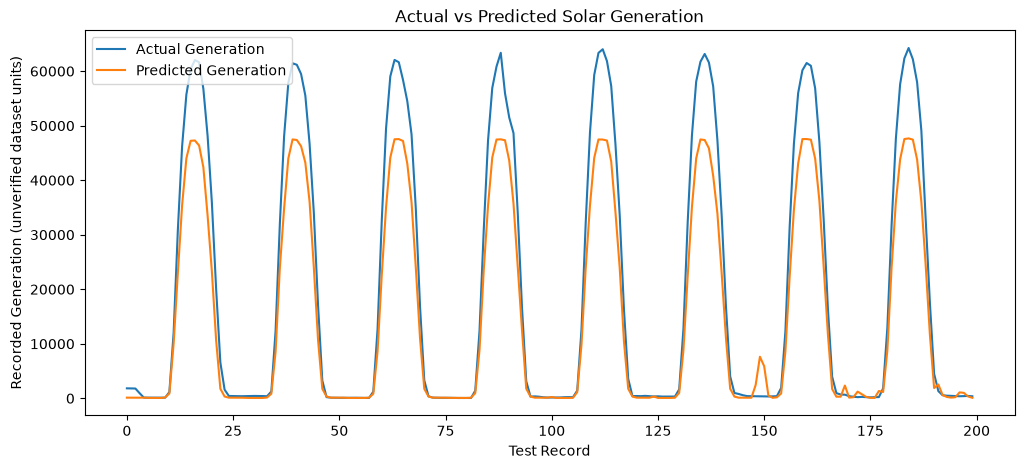

In [67]:
# Plot actual and predicted generation

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:200],
    label="Actual Generation"
)

plt.plot(
    test_predictions[:200],
    label="Predicted Generation"
)

plt.title("Actual vs Predicted Solar Generation")

plt.xlabel("Test Record")

plt.ylabel("Recorded Generation (unverified dataset units)")

plt.legend()

plt.show()

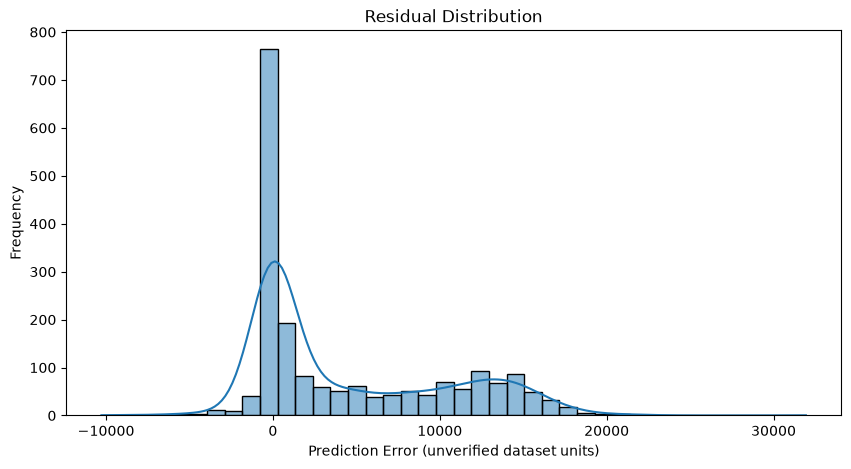

In [68]:
# Calculate residuals

residuals = y_test.values - test_predictions

# Plot residual distribution

plt.figure(figsize=(10, 5))

sns.histplot(residuals, bins=40, kde=True)

plt.title("Residual Distribution")

plt.xlabel("Prediction Error (unverified dataset units)")

plt.ylabel("Frequency")

plt.show()

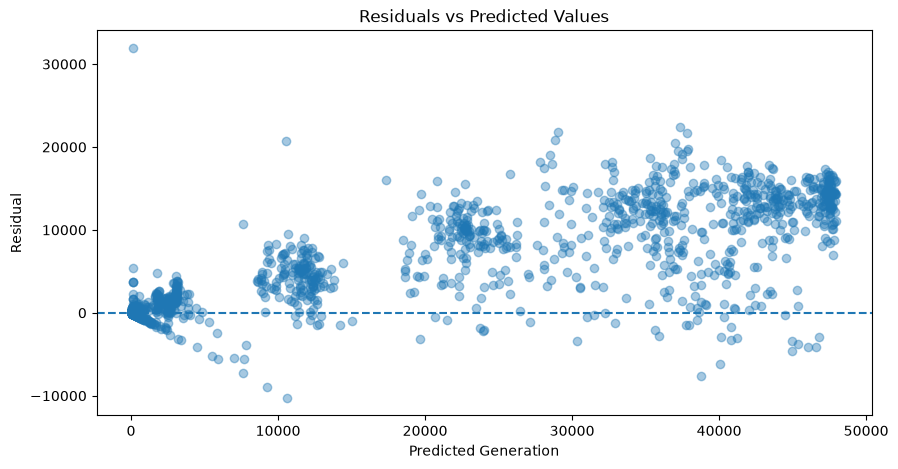

In [69]:
# Plot residuals against predicted values

plt.figure(figsize=(10, 5))

plt.scatter(
    test_predictions,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residuals vs Predicted Values")

plt.xlabel("Predicted Generation")

plt.ylabel("Residual")

plt.show()

In [70]:
# Import Joblib for saving and loading models

import joblib

In [71]:
# Save the selected model

joblib.dump(best_model, "solar_generation_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [72]:
# Save the scaler

joblib.dump(scaler, "solar_generation_scaler.pkl")

# Save the feature names and their order

joblib.dump(feature_columns, "solar_feature_names.pkl")

print("Scaler and feature names saved successfully.")

Scaler and feature names saved successfully.


In [73]:
# Load the saved model

loaded_model = joblib.load("solar_generation_model.pkl")

# Load the saved scaler

loaded_scaler = joblib.load("solar_generation_scaler.pkl")

# Load the feature names

loaded_feature_columns = joblib.load("solar_feature_names.pkl")

print("Saved files loaded successfully.")

Saved files loaded successfully.


In [74]:
# Select one sample from the test dataset

sample_input = X_test.iloc[[0]]

# Display the sample input

sample_input

,ALLSKY_SFC_SW_DWN,T2M,T2MDEW,RH2M,WS10M,Hour,Month,DayOfYear
11036,0.0,27.7,19.38,60.49,1.93,20,4,94


In [75]:
# Check the feature names and order

print("Expected Features:")
print(loaded_feature_columns)

print("\nSample Input Features:")
print(sample_input.columns.tolist())

# Verify the feature order

if sample_input.columns.tolist() == loaded_feature_columns:
    print("\nFeature names and order match.")
else:
    print("\nFeature names or order do not match.")

Expected Features:
['ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M', 'WS10M', 'Hour', 'Month', 'DayOfYear']

Sample Input Features:
['ALLSKY_SFC_SW_DWN', 'T2M', 'T2MDEW', 'RH2M', 'WS10M', 'Hour', 'Month', 'DayOfYear']

Feature names and order match.


In [76]:
# Prepare the sample input

if best_model_name == "Ridge Regression":

    sample_input_final = loaded_scaler.transform(sample_input)

else:

    sample_input_final = sample_input

# Generate the prediction

sample_prediction = loaded_model.predict(sample_input_final)

print(
    "Predicted Generation (unverified dataset units):",
    sample_prediction[0]
)

print(
    "Actual Generation (unverified dataset units):",
    y_test.iloc[0]
)

Predicted Generation (unverified dataset units): 120.9086856372229
Actual Generation (unverified dataset units): 1831.43


In [77]:
# Display the final model information

print("SOLAR GENERATION PREDICTION MODEL")
print("---------------------------------")

print("Selected Model:", best_model_name)

print("Number of Input Features:", len(feature_columns))

print("Training Records:", len(X_train))

print("Validation Records:", len(X_validation))

print("Testing Records:", len(X_test))

print("\nFinal Test Results")

print("MAE:", test_mae)

print("RMSE:", test_rmse)

print("R2:", test_r2)

print("\nSaved Files:")

print("1. solar_generation_model.pkl")

print("2. solar_generation_scaler.pkl")

print("3. solar_feature_names.pkl")

print("\nTarget Unit: UNVERIFIED DATASET UNITS")

print("Prediction Type: Same-hour estimation using same-hour weather observations")

SOLAR GENERATION PREDICTION MODEL
---------------------------------
Selected Model: Tuned Random Forest
Number of Input Features: 8
Training Records: 9088
Validation Records: 1948
Testing Records: 1948

Final Test Results
MAE: 4717.039534768683
RMSE: 7413.105114571751
R2: 0.8946355494054417

Saved Files:
1. solar_generation_model.pkl
2. solar_generation_scaler.pkl
3. solar_feature_names.pkl

Target Unit: UNVERIFIED DATASET UNITS
Prediction Type: Same-hour estimation using same-hour weather observations
